# Simulated Annealing Implementation

This notebook demonstrates the **Simulated Annealing** algorithm, a probabilistic technique for approximating the global optimum of a given function.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the objective function to minimize
def objective_function(x):
    return x**2 + 10 * np.sin(x)

# Simulated Annealing Algorithm
def simulated_annealing(objective, bounds, n_iterations, step_size, temp):
    # Generate an initial point
    best = bounds[:, 0] + np.random.rand(len(bounds)) * (bounds[:, 1] - bounds[:, 0])
    best_eval = objective(best[0])

    curr, curr_eval = best, best_eval
    history = [curr[0]]

    for i in range(n_iterations):
        # Take a step
        candidate = curr + np.random.randn(len(bounds)) * step_size
        # Keep within bounds
        candidate[0] = np.clip(candidate[0], bounds[0, 0], bounds[0, 1])
        candidate_eval = objective(candidate[0])

        # Check if we should keep the new point
        if candidate_eval < best_eval:
            best, best_eval = candidate, candidate_eval
            history.append(best[0])
            print(f"> Iteration {i}: New Best f({best[0]:.4f}) = {best_eval:.4f}")

        # Difference in evaluation
        diff = candidate_eval - curr_eval
        # Calculate temperature
        t = temp / float(i + 1)
        # Calculate metropolis acceptance criterion
        metropolis = np.exp(-diff / t)

        # Accept the worst state according to the probability
        if diff < 0 or np.random.rand() < metropolis:
            curr, curr_eval = candidate, candidate_eval

    return [best[0], best_eval, history]

In [ ]:
# Set random seed for reproducibility
np.random.seed(42)

# Define configuration
bounds = np.asarray([[-10.0, 10.0]])
n_iterations = 1000
step_size = 0.5
temp = 10.0

# Run the algorithm
best, score, history = simulated_annealing(objective_function, bounds, n_iterations, step_size, temp)
print(f'\nOptimization complete.')
print(f'Best Solution: f({best:.4f}) = {score:.4f}')

> Iteration 2: New Best f(-2.1161) = -4.0720
> Iteration 3: New Best f(-1.7324) = -6.8687
> Iteration 5: New Best f(-1.6958) = -7.0461
> Iteration 8: New Best f(-1.2876) = -7.9438
> Iteration 43: New Best f(-1.3026) = -7.9457
> Iteration 58: New Best f(-1.3065) = -7.9458

Optimization complete.
Best Solution: f(-1.3065) = -7.9458


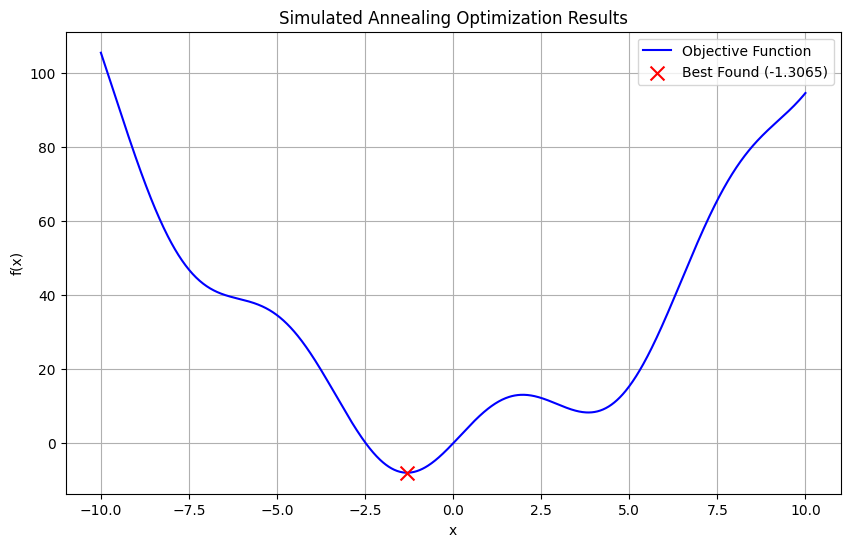

In [ ]:
# Plot the results
x = np.linspace(-10, 10, 1000)
y = objective_function(x)

plt.figure(figsize=(10, 6))
plt.plot(x, y, label='Objective Function', color='blue')
plt.scatter(best, score, color='red', marker='x', s=100, label=f'Best Found ({best:.4f})', zorder=5)
plt.title('Simulated Annealing Optimization Results')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True)
plt.show()

## 8 Queens Puzzle Solver

The 8 Queens puzzle is the problem of placing eight chess queens on an 8×8 chessboard so that no two queens threaten each other. Below is a solution using a classic backtracking algorithm.

In [ ]:
def is_safe(board, row, col):
    # Check this row on left side
    for i in range(col):
        if board[row][i] == 1:
            return False

    # Check upper diagonal on left side
    for i, j in zip(range(row, -1, -1), range(col, -1, -1)):
        if board[i][j] == 1:
            return False

    # Check lower diagonal on left side
    for i, j in zip(range(row, 8, 1), range(col, -1, -1)):
        if board[i][j] == 1:
            return False

    return True

def solve_nq_util(board, col):
    # Base case: If all queens are placed
    if col >= 8:
        return True

    # Consider this column and try placing this queen in all rows one by one
    for i in range(8):
        if is_safe(board, i, col):
            # Place this queen
            board[i][col] = 1

            # Recur to place rest of the queens
            if solve_nq_util(board, col + 1):
                return True

            # If placing queen in board[i][col] doesn't lead to a solution, backtrack
            board[i][col] = 0

    return False

def solve_8_queens():
    board = [[0]*8 for _ in range(8)]
    if not solve_nq_util(board, 0):
        print("Solution does not exist")
        return None
    return np.array(board)

board_solution = solve_8_queens()
display(board_solution)

array([[1, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1, 0],
       [0, 0, 0, 0, 1, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 1],
       [0, 1, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 1, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 1, 0, 0],
       [0, 0, 1, 0, 0, 0, 0, 0]])

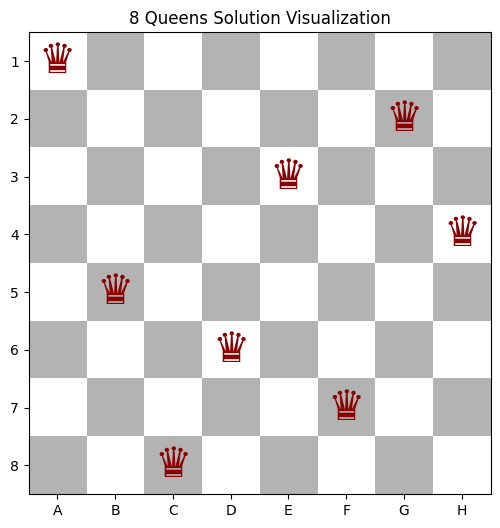

In [ ]:
# Visualize the 8 Queens solution
if board_solution is not None:
    fig, ax = plt.subplots(figsize=(6, 6))
    # Create a checkerboard background
    checkerboard = np.indices((8, 8)).sum(axis=0) % 2
    ax.imshow(checkerboard, cmap='binary', alpha=0.3)

    # Draw Queens on the board
    for r in range(8):
        for c in range(8):
            if board_solution[r, c] == 1:
                ax.text(c, r, '♛', fontsize=30, ha='center', va='center', color='darkred')

    ax.set_xticks(range(8))
    ax.set_yticks(range(8))
    ax.set_xticklabels(['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H'])
    ax.set_yticklabels(range(1, 9))
    ax.grid(False)
    plt.title("8 Queens Solution Visualization")
    plt.show()